# Оценка эффекта нового алгоритма ранжирования ресторанов (DiD)

**Шестаков Даниил**

## Постановка задачи

Сервис доставки еды внедряет новый алгоритм ранжирования ресторанов в ленте приложения. Гипотеза: более релевантная выдача увеличивает число заказов.

**Дизайн.** Рандомизация по пользователям невозможна (раздел 2). С 6 апреля 2026 г. алгоритм включён в трёх крупнейших городах (Москва, Санкт-Петербург, Новосибирск); остальные 7 городов остаются на старом алгоритме и служат контролем.

**Метрики:**

- основная — заказы на пользователя в день (orders per user, OPU);
- guardrail — среднее время доставки, мин (алгоритм может смещать спрос к загруженным ресторанам) и средний чек, ₽.

**Данные:** панель «город × день», 10 городов, 9 недель до и 4 недели после запуска (02.02.2026 – 03.05.2026). Данные синтетические, с заложенным истинным эффектом +7% к OPU: это позволяет проверить, восстанавливает ли метод известный эффект.

## 0. Генерация данных

Заложенные свойства:

- неслучайное назначение: пилот в трёх крупнейших городах;
- недельная сезонность, общая для всех городов (пик в субботу);
- общий тренд роста аудитории и индивидуальные тренды городов;
- общий весенний рост спроса (+4.5%), совпадающий с пост-периодом, — конфаундер для сравнения «до/после»;
- истинные эффекты: +7% к OPU, +0.45 мин ко времени доставки, 0 на средний чек.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats as sstats
from itertools import combinations
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEED = 3
rng = np.random.default_rng(SEED)

cities = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
          "Нижний Новгород", "Самара", "Воронеж", "Краснодар", "Пермь"]
treated = set(cities[:3])  # пилот — три крупнейших города, назначение не случайно
base_users = np.array([5200, 4800, 4400, 2600, 2400, 2200, 1800, 1600, 1400, 1200])

PRE_START, TREAT_DATE, END = "2026-02-02", "2026-04-06", "2026-05-03"
dates = pd.date_range(PRE_START, END, freq="D")

# Недельная сезонность спроса (общая для всех городов): минимум в понедельник, пик в субботу
DOW_MULT = {0: 0.92, 1: 0.95, 2: 0.97, 3: 1.00, 4: 1.08, 5: 1.15, 6: 1.05}

rows = []
for ci, city in enumerate(cities):
    freq0 = 0.30 + rng.normal(0, 0.010)        # базовая частота заказов на пользователя в городе
    deliv0 = 32 + rng.normal(0, 1.2)           # базовое время доставки, мин
    check0 = 950 + rng.normal(0, 60)           # базовый средний чек, ₽
    city_growth = rng.normal(0.0004, 0.00015)  # индивидуальный тренд роста города
    for t, d in enumerate(dates):
        post = d >= pd.Timestamp(TREAT_DATE)
        trend = (1.0006 ** t) * np.exp(city_growth * t)  # общий рост рынка + тренд города
        shock = 1.045 if post else 1.0                   # общий весенний подъём спроса, совпал с пост-периодом
        users = base_users[ci] * trend * (1 + rng.normal(0, 0.03))
        eff = 1.07 if (city in treated and post) else 1.0  # ИСТИННЫЙ эффект алгоритма: +7% к частоте заказов
        freq = freq0 * DOW_MULT[d.day_of_week] * shock * eff * (1 + rng.normal(0, 0.02))
        orders = users * freq
        deliv = (deliv0 + 6.0 * (DOW_MULT[d.day_of_week] - 1)   # по выходным доставка чуть дольше
                 + (0.45 if (city in treated and post) else 0)  # истинный эффект на guardrail: +0.45 мин
                 + rng.normal(0, 0.7))
        check = check0 * (1 + rng.normal(0, 0.02))              # эффекта на чек нет
        rows.append((d, city, city in treated, post, round(users), round(orders), deliv, check))

df = pd.DataFrame(rows, columns=["date", "city", "treated", "post", "users", "orders",
                                 "avg_delivery_min", "avg_check"])
df["opu"] = df["orders"] / df["users"]   # основная метрика: заказы на пользователя в день
df["log_opu"] = np.log(df["opu"])        # лог-шкала -> коэффициенты читаются как проценты
df["treat_post"] = (df["treated"] & df["post"]).astype(int)
df["city_id"] = df["city"].map({c: i for i, c in enumerate(cities)})

df.to_csv("ab_final_data.csv", index=False)  # сохраняем датасет для воспроизводимости
print(f"Размер панели: {df.shape[0]} строк (10 городов x {df['date'].nunique()} дней)")
df.head()

Размер панели: 910 строк (10 городов x 91 дней)


,date,city,treated,post,users,orders,avg_delivery_min,avg_check,opu,log_opu,treat_post,city_id
0,2026-02-02,Москва,True,False,5129,1506,27.039,970.563,0.294,-1.225,0,0
1,2026-02-03,Москва,True,False,5070,1646,28.791,968.209,0.325,-1.125,0,0
2,2026-02-04,Москва,True,False,5166,1584,28.015,967.465,0.307,-1.182,0,0
3,2026-02-05,Москва,True,False,5290,1687,29.604,971.189,0.319,-1.143,0,0
4,2026-02-06,Москва,True,False,5223,1863,29.795,965.233,0.357,-1.031,0,0


## 1. Разведочный анализ данных и проверка предпосылок

### 1.1. Общий обзор

In [2]:
# Средние значения метрик по группам и периодам
overview = (df.groupby(["treated", "post"])
              .agg(users=("users", "mean"), orders=("orders", "mean"), opu=("opu", "mean"),
                   delivery_min=("avg_delivery_min", "mean"), check=("avg_check", "mean"))
              .rename(index={True: "тест", False: "контроль"}, level=0)
              .rename(index={True: "после", False: "до"}, level=1))
overview.round(3)

users    orders   opu  delivery_min   check
treated  post                                                 
контроль до    1,943.063   575.973 0.297        31.744 929.320
         после 2,025.592   625.168 0.309        31.716 929.907
тест     до    4,950.418 1,532.788 0.309        30.459 985.899
         после 5,155.429 1,780.595 0.345        30.946 987.614

Тестовые города в 2.5 раза крупнее контрольных по числу пользователей — следствие неслучайного выбора пилота.

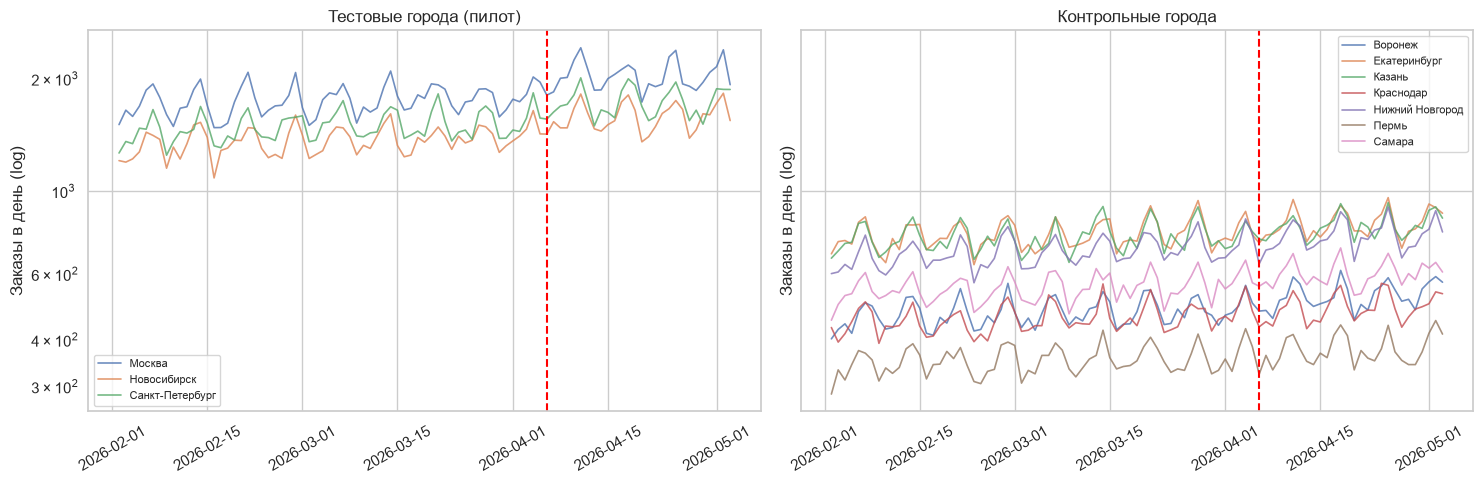

In [3]:
# Динамика заказов по городам
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, grp, title in zip(axes, [True, False],
                          ["Тестовые города (пилот)", "Контрольные города"]):
    for city, d in df[df["treated"] == grp].groupby("city"):
        ax.plot(d["date"], d["orders"], lw=1.2, alpha=0.8, label=city)
    ax.axvline(pd.Timestamp(TREAT_DATE), color="red", ls="--", lw=1.5)
    ax.set_title(title)
    ax.set_yscale("log")
    ax.set_ylabel("Заказы в день (log)")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=30)
axes[0].annotate("раскатка\n06.04.2026", xy=(pd.Timestamp(TREAT_DATE), 100),
                 color="red", fontsize=9, ha="left")
plt.tight_layout()
plt.show()

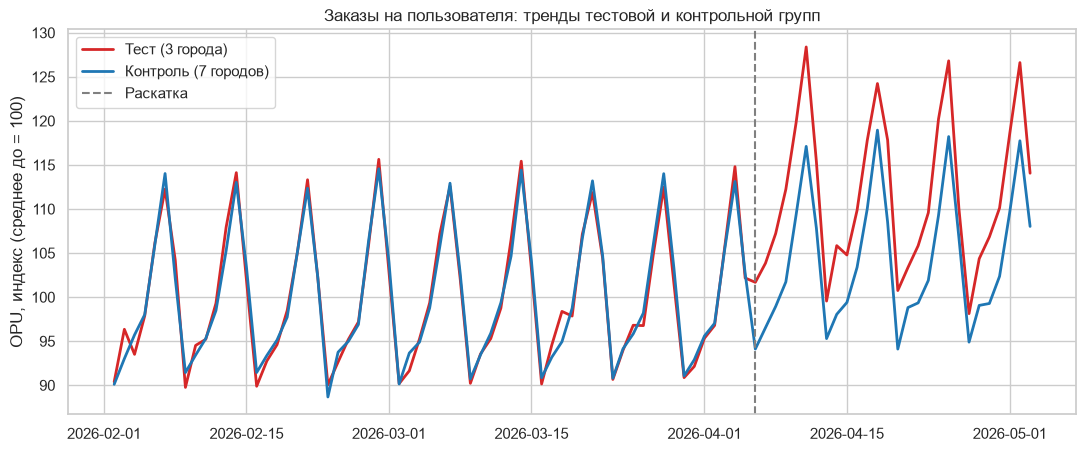

In [4]:
# Индексированная динамика OPU по группам (среднее пре-периода каждой группы = 100)
g = df.groupby(["treated", "date"])["opu"].mean().reset_index()
base = g[g["date"] < TREAT_DATE].groupby("treated")["opu"].mean()
g["idx"] = g.apply(lambda r: r["opu"] / base[r["treated"]] * 100, axis=1)

fig, ax = plt.subplots(figsize=(13, 5))
for grp, color, label in [(True, "tab:red", "Тест (3 города)"), (False, "tab:blue", "Контроль (7 городов)")]:
    d = g[g["treated"] == grp]
    ax.plot(d["date"], d["idx"], color=color, lw=2, label=label)
ax.axvline(pd.Timestamp(TREAT_DATE), color="grey", ls="--", lw=1.5, label="Раскатка")
ax.set_ylabel("OPU, индекс (среднее до = 100)")
ax.set_title("Заказы на пользователя: тренды тестовой и контрольной групп")
ax.legend()
plt.show()

**Наблюдения:**

1. Уровни метрик в группах различаются — города выбраны не случайно.
2. До запуска индексированные тренды OPU в группах совпадают: визуально предпосылка параллельных трендов выполняется (формальная проверка — event-study, раздел 3.2).
3. После запуска тестовая группа выше контрольной.
4. Есть общая для обеих групп недельная сезонность.

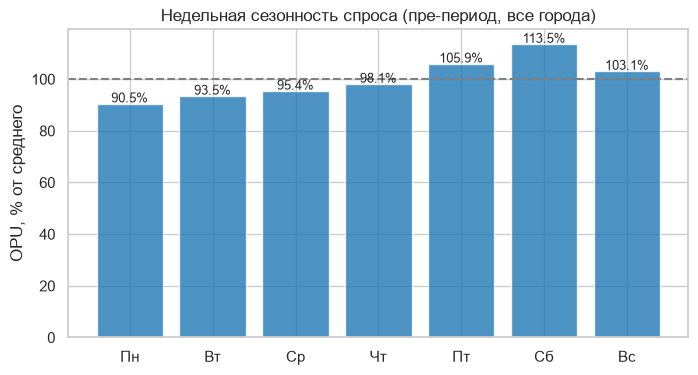

суббота: +13.5%, понедельник: -9.5% к среднему; размах 23.1 п.п.


In [5]:
# Недельная сезонность (пре-период): средний OPU по дням недели
pre = df[~df["post"]]
s = pre.groupby(pre["date"].dt.day_of_week)["opu"].mean()
s_rel = s / s.mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"], s_rel.values, color="tab:blue", alpha=0.8)
ax.axhline(100, color="grey", ls="--")
ax.set_ylabel("OPU, % от среднего")
ax.set_title("Недельная сезонность спроса (пре-период, все города)")
for i, v in enumerate(s_rel.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
plt.show()
print(
    f"суббота: {s_rel.loc[5] - 100:+.1f}%, понедельник: {s_rel.loc[0] - 100:+.1f}% к среднему; "
    f"размах {s_rel.max() - s_rel.min():.1f} п.п."
)

**Сезонность:** суббота +13.5% к среднему, понедельник −9.5%; профиль общий для всех городов. В DiD сезонность поглощается фиксированными эффектами даты; разная амплитуда по городам проверяется в разделе 3.4.

### 1.2. Баланс тестовых и контрольных городов до внедрения

t-тест Уэлча по средним городов за пре-период (3 против 7 городов). Рандомизации не было, поэтому SRM неприменим; основная диагностика отбора — баланс ковариат. При 10 наблюдениях мощность теста низкая, поэтому важны и сами величины различий.

In [6]:
bal = (pre.groupby(["city", "treated"])
          .agg(users=("users", "mean"), opu=("opu", "mean"),
               delivery=("avg_delivery_min", "mean"), check=("avg_check", "mean"))
          .reset_index())

rows = []
for col, name in [("users", "Пользователи/день"), ("opu", "OPU (заказы/польз.)"),
                  ("delivery", "Время доставки, мин"), ("check", "Средний чек, ₽")]:
    a, b = bal[bal["treated"]][col], bal[~bal["treated"]][col]
    tt = sstats.ttest_ind(a, b, equal_var=False)
    rows.append({"метрика": name, "тест (ср.)": a.mean(), "контроль (ср.)": b.mean(),
                 "разница, %": (a.mean() / b.mean() - 1) * 100, "p-value (Welch)": tt.pvalue})
balance = pd.DataFrame(rows).set_index("метрика")
balance.round(3)

,тест (ср.),контроль (ср.),"разница, %",p-value (Welch)
метрика,,,,
Пользователи/день,"4,950.418","1,943.063",154.774,0.000
OPU (заказы/польз.),0.309,0.297,4.104,0.313
"Время доставки, мин",30.459,31.744,-4.047,0.239
"Средний чек, ₽",985.899,929.320,6.088,0.090


**Выводы по балансу:**

- Пользователи: в тестовых городах в 2.5 раза больше (p < 0.001) — назначение связано с размером города, сравнение уровней между группами смещено.
- OPU, время доставки, средний чек: значимых различий нет (p > 0.05), но OPU в тестовых городах выше на 4%.
- Нужен метод, устраняющий постоянные различия городов и общие временные шоки, — DiD с фиксированными эффектами города и даты.

## 2. Выбор метода причинного вывода

### Почему не A/B-тест на пользователях

1. **Интерференция (нарушение SUTVA).** Ранжирование перераспределяет спрос между ресторанами и нагрузку на курьеров внутри города, поэтому затрагивает и пользователей контроля в том же городе. Единица назначения — город.
2. **Операционные ограничения:** индекс ресторанов и логистика общие для города.

### Сравнение методов

| Метод | Применимость | Вывод |
|---|---|---|
| DiD | Панель «город × день», есть пре- и пост-период, тест и контроль; 9 недель пре-периода для проверки параллельных трендов | Основной метод |
| RDD | Нет непрерывной переменной назначения с порогом | Не применим |
| PSM | 10 городов (3 против 7) — недостаточно для матчинга; PSM учитывает только наблюдаемые признаки, но не различия трендов | Не применим |
| IV | Нет инструмента, влияющего на назначение и не влияющего на спрос напрямую | Не применим |

**Спецификация** — DiD с двусторонними фиксированными эффектами (TWFE):

$$\log(OPU_{ct}) = \beta \cdot (Treat_c \times Post_t) + \alpha_c + \delta_t + \varepsilon_{ct},$$

где $\alpha_c$ — эффекты городов (постоянные различия уровней, в том числе из-за отбора по размеру), $\delta_t$ — эффекты дат (общий тренд, недельная сезонность, весенний рост спроса). Стандартные ошибки кластеризованы по городу; ДИ и p-value — по t-распределению с $G - 1$ степенями свободы.

**Альтернативный дизайн:** кластерный RCT — случайный выбор городов для пилота из большего числа городов, либо switchback (чередование алгоритмов по временным окнам внутри города). Здесь пилот запускался в трёх крупнейших городах по решению бизнеса, поэтому используется квазиэкспериментальный DiD.

**Ограничение:** 10 кластеров, из них 3 тестовых — кластерные SE могут быть неточными. Дополнительно используется пермутационный тест (раздел 3.5).

## 3. Оценка эффектов

### 3.1. Базовая DiD-спецификация

In [7]:
G = df["city"].nunique()                 # число кластеров
tcrit = sstats.t.ppf(0.975, G - 1)       # t-критическое с G-1 ст. св.

def did(data, rhs="treat_post + C(city) + C(date)", y="log_opu"):
    # DiD-регрессия; SE кластеризованы по городу, ДИ и p-value по t с (число городов - 1) ст. св.
    m = smf.ols(f"{y} ~ {rhs}", data=data).fit(
        cov_type="cluster", cov_kwds={"groups": data["city"]}, use_t=True
    )
    lo, hi = m.conf_int().loc["treat_post"]
    return m.params["treat_post"], lo, hi, m.pvalues["treat_post"]

beta, lo, hi, pval = did(df)
print(f"DiD-оценка (log OPU):  beta = {beta:.4f},  SE = {(hi - lo) / 2 / tcrit:.4f}")
print(f"95% ДИ (t с {G-1} ст. св.):   [{lo:.4f}; {hi:.4f}],  p-value = {pval:.2e}")
print(f"В процентах: эффект = {np.expm1(beta) * 100:.2f}%,  "
      f"ДИ = [{np.expm1(lo) * 100:.2f}%; {np.expm1(hi) * 100:.2f}%]")

DiD-оценка (log OPU):  beta = 0.0676,  SE = 0.0055
95% ДИ (t с 9 ст. св.):   [0.0552; 0.0801],  p-value = 6.26e-07
В процентах: эффект = 7.00%,  ДИ = [5.67%; 8.33%]


**Результат:** OPU +7.0%, 95% ДИ [+5.7%; +8.3%], p < 0.001. Истинный эффект (+7%) внутри интервала.

### 3.2. Event-study: параллельные тренды и динамика эффекта

Коэффициенты «тест × неделя» относительно недели −1 (последней до запуска).

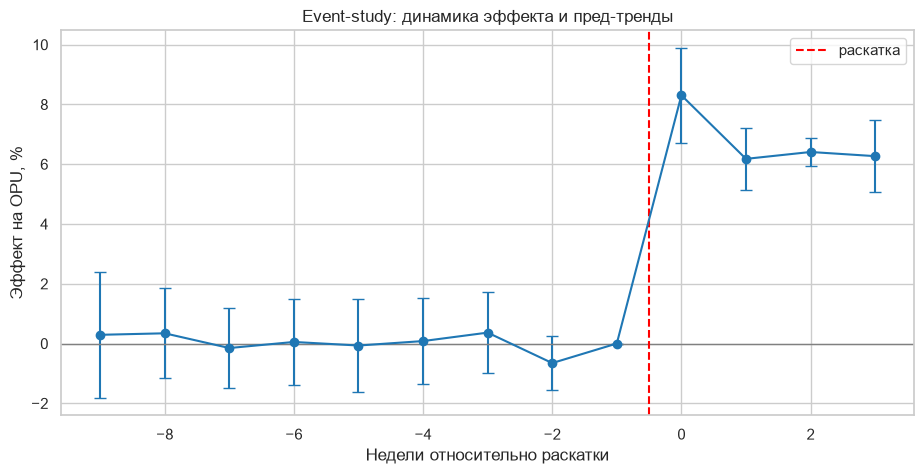

Совместный F-тест пред-трендов (недели -9..-2): F = 0.354, p-value = 0.944
Макс. |пред-тренд|: 0.65% (против эффекта ~7.0%)
Автокорреляция остатков (лаг 1 день) внутри городов: от -0.14 до +0.20
Эффект по неделям после запуска, % [95% ДИ]:
  неделя 0: +8.7 [+6.9; +10.4]
  неделя 1: +6.4 [+5.3; +7.5]
  неделя 2: +6.6 [+6.1; +7.1]
  неделя 3: +6.5 [+5.2; +7.8]


In [8]:
# Недельные лид/лаг-дамми относительно даты раскатки (база — неделя -1)
df["week_rel"] = ((df["date"] - pd.Timestamp(TREAT_DATE)).dt.days // 7).clip(-9, 3)
weeks = sorted(w for w in df["week_rel"].unique() if w != -1)
ev_cols = []
for w in weeks:
    name = f"ev_m{-w}" if w < 0 else f"ev_{w}"
    df[name] = ((df["week_rel"] == w) & df["treated"]).astype(int)
    ev_cols.append(name)

m_ev = smf.ols("log_opu ~ " + " + ".join(ev_cols) + " + C(city) + C(date)", data=df).fit(
    cov_type="cluster", cov_kwds={"groups": df["city"]})
est = pd.DataFrame({"week": weeks,
                    "beta": [m_ev.params[c] for c in ev_cols],
                    "se": [m_ev.bse[c] for c in ev_cols]})
est = pd.concat([est, pd.DataFrame({"week": [-1], "beta": [0.0], "se": [0.0]})]).sort_values("week")

fig, ax = plt.subplots(figsize=(11, 5))
ax.errorbar(est["week"], est["beta"] * 100, yerr=tcrit * est["se"] * 100,
            fmt="o-", capsize=4, color="tab:blue")
ax.axhline(0, color="grey", lw=1)
ax.axvline(-0.5, color="red", ls="--", lw=1.5, label="раскатка")
ax.set_xlabel("Недели относительно раскатки")
ax.set_ylabel("Эффект на OPU, %")
ax.set_title("Event-study: динамика эффекта и пред-тренды")
ax.legend()
plt.show()

# Совместный тест пред-трендов: H0 — коэффициенты недель -9..-2 равны 0.
# Кластерный тест 8 ограничений при 10 кластерах ненадёжен (ранг кластерной ковариации <= G-1),
# поэтому используется обычный F-тест. Он корректен, если остатки внутри города
# не коррелированы во времени — это проверяется ниже.
m_ev_cls = smf.ols("log_opu ~ " + " + ".join(ev_cols) + " + C(city) + C(date)", data=df).fit()
pre_names = [f"ev_m{w}" for w in range(2, 10)]
fres = m_ev_cls.f_test(", ".join(f"{n} = 0" for n in pre_names))
print(f"Совместный F-тест пред-трендов (недели -9..-2): F = {float(fres.fvalue):.3f}, "
      f"p-value = {float(fres.pvalue):.3f}")
print(f"Макс. |пред-тренд|: {max(abs(m_ev.params[n]) for n in pre_names) * 100:.2f}% "
      f"(против эффекта ~{np.expm1(beta) * 100:.1f}%)")

resid_ac = (
    df.assign(resid=m_ev_cls.resid)
    .sort_values("date")
    .groupby("city")["resid"]
    .apply(lambda r: r.autocorr(lag=1))
)
print(f"Автокорреляция остатков (лаг 1 день) внутри городов: от {resid_ac.min():+.2f} до {resid_ac.max():+.2f}")

print("Эффект по неделям после запуска, % [95% ДИ]:")
for w, b, s in est[est["week"] >= 0][["week", "beta", "se"]].itertuples(index=False):
    print(f"  неделя {int(w)}: {np.expm1(b) * 100:+.1f} "
          f"[{np.expm1(b - tcrit * s) * 100:+.1f}; {np.expm1(b + tcrit * s) * 100:+.1f}]")

**Выводы:**

- Коэффициенты недель −9…−2 близки к нулю (max |β| = 0.65%), совместный F-тест p = 0.94 — параллельные тренды не отвергаются, эффекта предвосхищения нет.
- Автокорреляция остатков внутри городов от −0.14 до +0.20 — в пределах шума при 91 наблюдении на город (SE ≈ 0.1), обычный F-тест применим.
- После запуска: +8.7% [+6.9; +10.4] в неделю 0, +6.4…+6.6% в недели 1–3. Все интервалы выше нуля и пересекаются; затухания после первой недели нет. Более высокая оценка недели 0 может отражать эффект новизны — её стоит отслеживать после раскатки.

### 3.3. Плацебо-проверки и стабильность состава

In [9]:
# Плацебо 1: фиктивная дата раскатки за 4 недели до реальной (только пре-период).
# Если метод находит «эффект» там, где его не было, — спецификация сломана.
d_pl = df[~df["post"]].copy()
fake_date = pd.Timestamp(TREAT_DATE) - pd.Timedelta(days=28)
d_pl["treat_post"] = (d_pl["treated"] & (d_pl["date"] >= fake_date)).astype(int)
b_pl, lo_pl, hi_pl, p_pl = did(d_pl)
print(f"Плацебо-дата: эффект = {np.expm1(b_pl) * 100:+.2f}%, "
      f"ДИ [{np.expm1(lo_pl) * 100:+.2f}%; {np.expm1(hi_pl) * 100:+.2f}%], p = {p_pl:.3f}")

# Плацебо 2 (стабильность состава): эффект на log(users) должен быть нулевым —
# алгоритм меняет конверсию, а не трафик. Это аналог SRM-проверки из модуля 1:
# если бы доля пользователей в тестовых городах изменилась, сравнение OPU было бы сомнительным.
b_u, lo_u, hi_u, p_u = did(df, y="np.log(users)")
print(f"Состав (log users): эффект = {np.expm1(b_u) * 100:+.2f}%, "
      f"ДИ [{np.expm1(lo_u) * 100:+.2f}%; {np.expm1(hi_u) * 100:+.2f}%], p = {p_u:.3f}")

Плацебо-дата: эффект = -0.15%, ДИ [-1.00%; +0.71%], p = 0.710
Состав (log users): эффект = +0.01%, ДИ [-1.93%; +1.99%], p = 0.992


Плацебо-дата: эффект −0.15%, 95% ДИ [−1.00%; +0.71%], p = 0.71. Состав пользователей не изменился: +0.01%, p = 0.99. Оценка не объясняется спецификацией или изменением аудитории.

### 3.4. Робастность к спецификации

Базовая модель сравнивается с моделями: + линейные тренды городов; + эффекты «город × день недели»; короткое пост-окно (2 недели); исключение по одному тестовому городу.

In [10]:
import warnings

specs = {}
specs["Базовая (FE города + FE даты)"] = did(df)

# (а) Городские линейные тренды: у каждого города свой наклон тренда.
# Добавляем 9 наклонов (без референсного города): 10 наклонов были бы коллинеарны с FE дат.
df["t"] = (df["date"] - df["date"].min()).dt.days
for i in range(1, G):
    df[f"trend_{i}"] = df["t"] * (df["city_id"] == i)
rhs_tr = "treat_post + C(city) + C(date) + " + " + ".join(f"trend_{i}" for i in range(1, G))
specs["+ индивидуальные тренды городов"] = did(df, rhs_tr)

# (б) FE город x день-недели: разная амплитуда недельной сезонности по городам.
# По одному референсному городу на каждый день недели (иначе коллинеарность с FE дат).
df["dow"] = df["date"].dt.day_of_week
cd_cols = []
for i in range(1, G):
    for w in range(7):
        col = f"cd_{i}_{w}"
        df[col] = ((df["city_id"] == i) & (df["dow"] == w)).astype(int)
        cd_cols.append(col)
rhs_cd = "treat_post + C(date) + " + " + ".join(cd_cols)
with warnings.catch_warnings():
    # Для части из 63 дамми кластерная ковариация при 10 кластерах вырождена,
    # statsmodels предупреждает о NaN в их SE. На SE treat_post это не влияет.
    warnings.simplefilter("ignore")
    specs["+ FE город x день недели"] = did(df, rhs_cd)

# (в) Короткое окно: только первые 2 недели пост-периода
sub2w = df[(~df["post"]) | (df["date"] < pd.Timestamp(TREAT_DATE) + pd.Timedelta(days=14))]
specs["Окно: 2 недели после"] = did(sub2w)

# (г) Leave-one-out: исключаем по одному тестовому городу
for c in sorted(treated):
    specs[f"Без г. {c}"] = did(df[df["city"] != c])

rob = pd.DataFrame(specs, index=["beta", "lo", "hi", "p"]).T
rob[["эффект, %", "ДИ низ, %", "ДИ верх, %"]] = np.expm1(rob[["beta", "lo", "hi"]]) * 100
rob.drop(columns=["beta", "lo", "hi"]).round(3)

,p,"эффект, %","ДИ низ, %","ДИ верх, %"
Базовая (FE города + FE даты),0.000,6.995,5.672,8.335
+ индивидуальные тренды городов,0.000,7.600,6.419,8.794
+ FE город x день недели,0.000,6.995,5.626,8.382
Окно: 2 недели после,0.000,7.479,5.797,9.189
Без г. Москва,0.000,7.046,5.093,9.035
Без г. Новосибирск,0.000,6.456,5.503,7.419
Без г. Санкт-Петербург,0.000,7.486,6.278,8.707


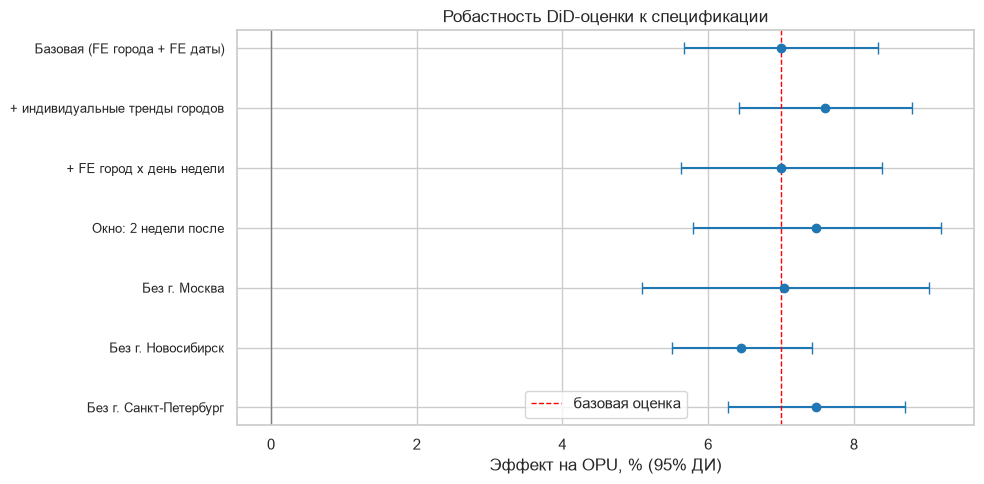

In [11]:
# Forest plot по спецификациям
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(rob))[::-1]
ax.errorbar(rob["эффект, %"], y,
            xerr=[rob["эффект, %"] - rob["ДИ низ, %"], rob["ДИ верх, %"] - rob["эффект, %"]],
            fmt="o", capsize=4, color="tab:blue")
ax.axvline(0, color="grey", lw=1)
ax.axvline(np.expm1(beta) * 100, color="red", ls="--", lw=1, label="базовая оценка")
ax.set_yticks(y)
ax.set_yticklabels(rob.index, fontsize=9)
ax.set_xlabel("Эффект на OPU, % (95% ДИ)")
ax.set_title("Робастность DiD-оценки к спецификации")
ax.legend()
plt.tight_layout()
plt.show()

**Вывод:** оценка лежит в диапазоне +6.5…+7.6% при всех спецификациях: не зависит от окна, от отдельного тестового города, от индивидуальных трендов и городской сезонности.

### 3.5. Пермутационный тест (randomization inference)

Перебор всех $\binom{10}{3} = 120$ вариантов выбора трёх «тестовых» городов; для каждого — DiD-коэффициент. p-value — доля вариантов с $|\beta|$ не меньше фактического. Минимально возможное значение — $1/120 \approx 0.008$.

Фактическая оценка: 0.0676
Плацебо-распределение: mean = -0.0006, 95% перцентиль |beta| = 0.0382
Пермутационный p-value = 0.0083


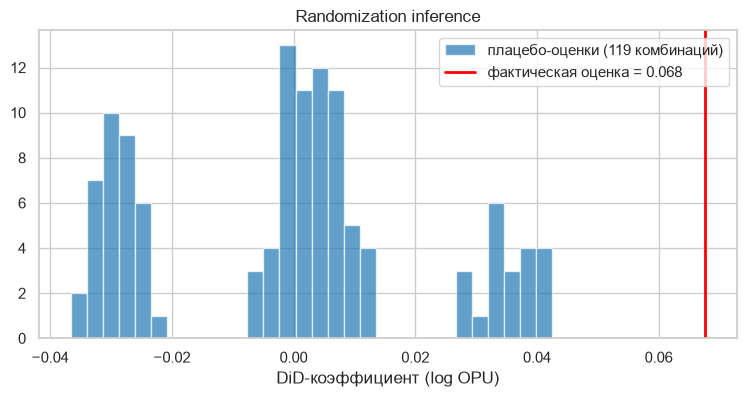

In [12]:
def did_plain(data):
    # DiD-коэффициент без кластеризации (нужна только точечная статистика)
    return smf.ols("log_opu ~ tp + C(city) + C(date)", data=data).fit().params["tp"]

perm_stats, actual = [], None
for combo in combinations(cities, 3):
    d = df.assign(tp=(df["city"].isin(combo) & df["post"]).astype(int))
    coef = did_plain(d)
    if set(combo) == treated:
        actual = coef
    else:
        perm_stats.append(coef)
perm_stats = np.array(perm_stats)

p_perm = (1 + (np.abs(perm_stats) >= abs(actual)).sum()) / (len(perm_stats) + 1)
print(f"Фактическая оценка: {actual:.4f}")
print(f"Плацебо-распределение: mean = {perm_stats.mean():.4f}, "
      f"95% перцентиль |beta| = {np.percentile(np.abs(perm_stats), 95):.4f}")
print(f"Пермутационный p-value = {p_perm:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(perm_stats, bins=30, color="tab:blue", alpha=0.7, label="плацебо-оценки (119 комбинаций)")
ax.axvline(actual, color="red", lw=2, label=f"фактическая оценка = {actual:.3f}")
ax.set_xlabel("DiD-коэффициент (log OPU)")
ax.set_title("Randomization inference")
ax.legend()
plt.show()

Фактическая оценка (0.068) больше по модулю, чем все 119 плацебо-оценок (95-й перцентиль $|\beta|$ = 0.038). Пермутационный p = 1/120 ≈ 0.008 — минимально возможный при 10 городах. Вывод не зависит от кластерной асимптотики.

## 4. Guardrail-анализ

Та же DiD-спецификация для времени доставки и среднего чека; поправка Холма на две гипотезы.

In [13]:
b_d, lo_d, hi_d, p_d = did(df, y="avg_delivery_min")
b_c, lo_c, hi_c, p_c = did(df, y="avg_check")

base_deliv = df[~df["post"]]["avg_delivery_min"].mean()
print(f"Время доставки: эффект = {b_d:+.3f} мин, ДИ [{lo_d:+.3f}; {hi_d:+.3f}], p = {p_d:.2e}")
print(f"  (база {base_deliv:.1f} мин -> изменение {b_d / base_deliv * 100:+.1f}%)")
print(f"Средний чек:    эффект = {b_c:+.2f} ₽,   ДИ [{lo_c:+.2f}; {hi_c:+.2f}], p = {p_c:.3f}")

# Поправка Холма на 2 guardrail-теста
rej, p_holm, _, _ = multipletests([p_d, p_c], alpha=0.05, method="holm")
guard = pd.DataFrame({"метрика": ["Время доставки, мин", "Средний чек, ₽"],
                      "эффект": [b_d, b_c], "ДИ низ": [lo_d, lo_c], "ДИ верх": [hi_d, hi_c],
                      "p-value": [p_d, p_c], "p-value (Holm)": p_holm,
                      "значим после Holm": rej}).set_index("метрика")
guard.round(4)

Время доставки: эффект = +0.515 мин, ДИ [+0.302; +0.727], p = 3.95e-04
  (база 31.4 мин -> изменение +1.6%)
Средний чек:    эффект = +1.13 ₽,   ДИ [-3.22; +5.48], p = 0.572


,эффект,ДИ низ,ДИ верх,p-value,p-value (Holm),значим после Holm
метрика,,,,,,
"Время доставки, мин",0.514,0.302,0.727,0.000,0.001,True
"Средний чек, ₽",1.129,-3.221,5.478,0.572,0.572,False


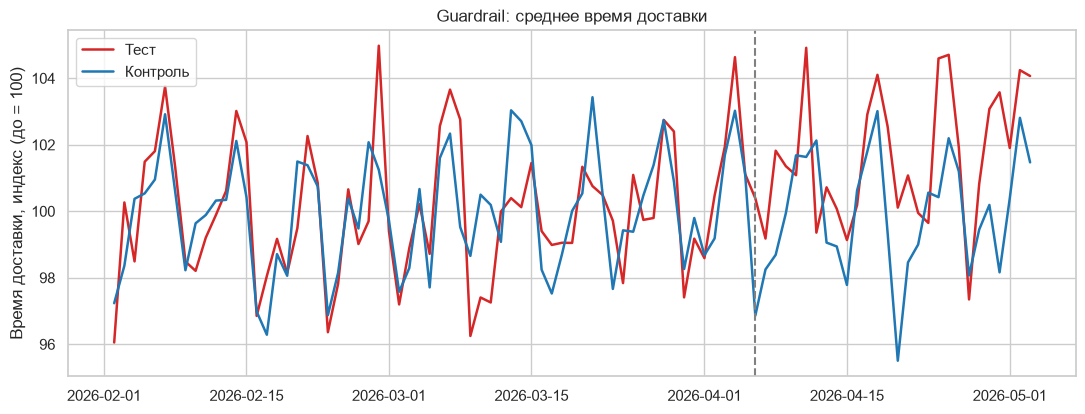

Верхняя граница 95% ДИ эффекта на доставку: 0.727 мин, порог 1.0 мин
Весь ДИ ниже порога: ухудшение практически незначимо


In [14]:
# Динамика времени доставки по группам (индекс: пре-период группы = 100)
gd = df.groupby(["treated", "date"])["avg_delivery_min"].mean().reset_index()
base_d = gd[gd["date"] < TREAT_DATE].groupby("treated")["avg_delivery_min"].mean()
gd["idx"] = gd.apply(lambda r: r["avg_delivery_min"] / base_d[r["treated"]] * 100, axis=1)

fig, ax = plt.subplots(figsize=(13, 4.5))
for grp, color, label in [(True, "tab:red", "Тест"), (False, "tab:blue", "Контроль")]:
    d = gd[gd["treated"] == grp]
    ax.plot(d["date"], d["idx"], color=color, lw=1.8, label=label)
ax.axvline(pd.Timestamp(TREAT_DATE), color="grey", ls="--")
ax.set_ylabel("Время доставки, индекс (до = 100)")
ax.set_title("Guardrail: среднее время доставки")
ax.legend()
plt.show()

# Практическая значимость: сравнение с заранее согласованным порогом
MARGIN_MIN = 1.0  # допустимое ухудшение времени доставки, мин (допущение: SLA операционной команды)
print(f"Верхняя граница 95% ДИ эффекта на доставку: {hi_d:.3f} мин, порог {MARGIN_MIN} мин")
if hi_d < MARGIN_MIN:
    print("Весь ДИ ниже порога: ухудшение практически незначимо")
else:
    print("ДИ заходит за порог: ухудшение может быть практически значимым")

**Выводы по guardrail:**

- Время доставки: +0.51 мин (+1.6% к базе 31.4 мин), 95% ДИ [+0.30; +0.73], p = 4·10⁻⁴, значимо после поправки Холма. Вероятный механизм — концентрация заказов на популярных ресторанах. Весь ДИ ниже допустимого порога 1 мин (порог — допущение, SLA операционной команды).
- Средний чек не изменился: +1.1 ₽, p = 0.57.
- Guardrail запуск не блокирует; время доставки — на мониторинг.

## 5. Продуктовый вывод

### 5.1. Бизнес-эффект от раскатки на все города

In [15]:
uplift = np.expm1(beta)  # относительный эффект на OPU
post = df[df["post"]]

# Фактические доп. заказы в пилотных городах (наблюдаемые заказы сверх контрфактика)
daily_t = post[post["treated"]].groupby("date")["orders"].sum().mean()
extra_t = daily_t * uplift / (1 + uplift)

# Прогноз доп. заказов при раскатке на 7 оставшихся городов
daily_c = post[~post["treated"]].groupby("date")["orders"].sum().mean()
extra_c = daily_c * uplift

avg_check = df["avg_check"].mean()
COMMISSION = 0.15  # комиссия сервиса с заказа

total_extra_day = extra_t + extra_c
gmv_year = total_extra_day * 365 * avg_check
rev_year = gmv_year * COMMISSION

print(f"Относительный эффект на заказы:          {uplift * 100:.1f}%")
print(f"Доп. заказы в пилотных городах (факт):   {extra_t:.0f} / день")
print(f"Прогноз доп. заказов в остальных городах: {extra_c:.0f} / день")
print(f"Итого после полной раскатки:             {total_extra_day:.0f} заказов/день "
      f"= {total_extra_day * 365 / 1000:.0f} тыс. заказов/год")
print(f"Прирост GMV:                             {gmv_year / 1e6:.0f} млн ₽/год")
print(f"Прирост выручки сервиса (комиссия {COMMISSION:.0%}): {rev_year / 1e6:.1f} млн ₽/год")

Относительный эффект на заказы:          7.0%
Доп. заказы в пилотных городах (факт):   349 / день
Прогноз доп. заказов в остальных городах: 306 / день
Итого после полной раскатки:             655 заказов/день = 239 тыс. заказов/год
Прирост GMV:                             226 млн ₽/год
Прирост выручки сервиса (комиссия 15%): 34.0 млн ₽/год


### 5.2. Рекомендация: внедрять во всех городах поэтапно

1. **Основная метрика:** OPU +7.0%, 95% ДИ [+5.7%; +8.3%]; результат подтверждён event-study, плацебо-проверками, пермутационным тестом и 7 спецификациями. При переносе эффекта на все города — ≈655 дополнительных заказов в день, ≈226 млн ₽ GMV и ≈34 млн ₽ выручки в год (комиссия 15% — допущение). Разработка уже выполнена; затраты на раскатку — настройка и мониторинг.
2. **Guardrail:** время доставки +0.5 мин — в пределах порога 1 мин; средний чек без изменений.
3. **Условия раскатки:**
   - мониторинг времени доставки с алертом при приближении к порогу; при превышении — учитывать загрузку ресторана в ранжировании;
   - поэтапное включение (2–3 города в неделю) с возможностью отката.
4. **Ограничения:** эффект измерен в крупных городах; в малых (другая плотность ресторанов и курьеров) он может отличаться — на первых этапах сравнивать раскатанные города с ещё не раскатанными тем же DiD. Горизонт — 4 недели; долгосрочный эффект требует отдельного контроля.

## 6. Бонус: наивные оценки и контроль сезонности

### 6.1. Наивные оценки

1. «До/после» в тестовых городах (без контрольной группы).
2. «Тест/контроль» в пост-периоде (без пре-периода).

Обе — t-тест Уэлча по log OPU город-дней.

In [16]:
# Наивная оценка 1: до vs после в тестовых городах (t-тест Уэлча по log OPU город-дней)
tr = df[df["treated"]]
a1, b1 = tr[tr["post"]]["log_opu"], tr[~tr["post"]]["log_opu"]
tt1 = sstats.ttest_ind(a1, b1, equal_var=False)
eff1 = a1.mean() - b1.mean()
ci1 = (eff1 - sstats.t.ppf(0.975, tt1.df) * np.sqrt(a1.var()/len(a1) + b1.var()/len(b1)),
       eff1 + sstats.t.ppf(0.975, tt1.df) * np.sqrt(a1.var()/len(a1) + b1.var()/len(b1)))

# Наивная оценка 2: тест vs контроль в пост-периоде
a2 = df[df["post"] & df["treated"]]["log_opu"]
b2 = df[df["post"] & ~df["treated"]]["log_opu"]
tt2 = sstats.ttest_ind(a2, b2, equal_var=False)
eff2 = a2.mean() - b2.mean()
ci2 = (eff2 - sstats.t.ppf(0.975, tt2.df) * np.sqrt(a2.var()/len(a2) + b2.var()/len(b2)),
       eff2 + sstats.t.ppf(0.975, tt2.df) * np.sqrt(a2.var()/len(a2) + b2.var()/len(b2)))

comp = pd.DataFrame({
    "оценка": ["Наивная «до/после» (тест)", "Наивная «тест/контроль» (пост)", "DiD (TWFE)"],
    "эффект, %": [np.expm1(eff1) * 100, np.expm1(eff2) * 100, np.expm1(beta) * 100],
    "ДИ низ, %": [np.expm1(ci1[0]) * 100, np.expm1(ci2[0]) * 100, np.expm1(lo) * 100],
    "ДИ верх, %": [np.expm1(ci1[1]) * 100, np.expm1(ci2[1]) * 100, np.expm1(hi) * 100],
}).set_index("оценка")
comp.round(2)

,"эффект, %","ДИ низ, %","ДИ верх, %"
оценка,,,
Наивная «до/после» (тест),11.550,9.040,14.120
Наивная «тест/контроль» (пост),11.360,8.910,13.870
DiD (TWFE),7.000,5.670,8.330


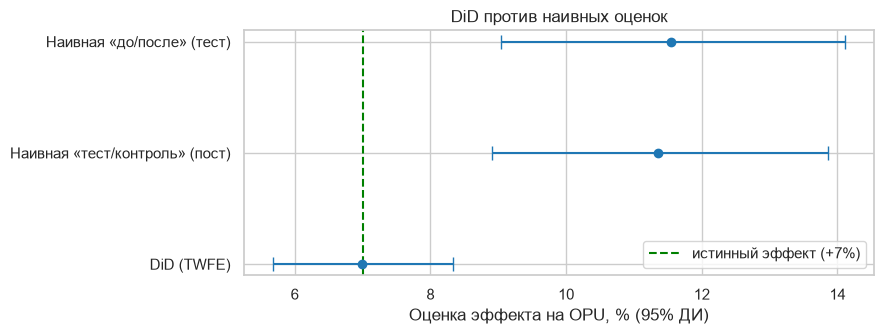

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.5))
y = np.arange(len(comp))[::-1]
ax.errorbar(comp["эффект, %"], y,
            xerr=[comp["эффект, %"] - comp["ДИ низ, %"], comp["ДИ верх, %"] - comp["эффект, %"]],
            fmt="o", capsize=5, color="tab:blue")
ax.axvline(7.0, color="green", ls="--", label="истинный эффект (+7%)")
ax.set_yticks(y)
ax.set_yticklabels(comp.index)
ax.set_xlabel("Оценка эффекта на OPU, % (95% ДИ)")
ax.set_title("DiD против наивных оценок")
ax.legend()
plt.tight_layout()
plt.show()

**Сравнение (истинный эффект +7%):**

- «До/после» (+11.6%) завышает эффект: включает общий весенний рост спроса (+4.5%), который пришёлся на пост-период. В DiD его убирают эффекты дат.
- «Тест/контроль» (+11.4%) завышает эффект: включает исходную разницу уровней OPU между крупными и малыми городами (+4% до запуска, раздел 1.2). В DiD её убирают эффекты городов.
- Обе наивные оценки значимы: значимость t-теста сама по себе не означает причинного эффекта.

### 6.2. Контроль сезонности и конфаундеров

- Эффекты дат $\delta_t$ — общие для всех городов недельная сезонность, тренд и весенний рост спроса.
- Эффекты «город × день недели» (раздел 3.4) — разная амплитуда сезонности по городам; оценка не изменилась.
- Линейные тренды городов (раздел 3.4) — разная долгосрочная динамика.
- Не контролируются шоки, затронувшие только тестовые города одновременно с запуском. Косвенно против них — стабильный эффект по неделям (event-study) и неизменный состав пользователей (плацебо по users).

### Итог

| Критерий | Результат |
|---|---|
| Метод | DiD (TWFE); A/B по пользователям, RDD, PSM, IV неприменимы |
| Допущения | Пред-тренды: F-тест p = 0.94; плацебо-дата и плацебо по составу пройдены |
| Эффект на OPU | +7.0%, 95% ДИ [+5.7%; +8.3%]; пермутационный p ≈ 0.008; +6.5…+7.6% по 7 спецификациям |
| Guardrail | Доставка +0.5 мин (значимо, в пределах порога 1 мин); чек без изменений |
| Решение | Внедрять во всех городах поэтапно с мониторингом времени доставки |
| Наивные оценки | +11.4…+11.6% — завышены из-за сезонного роста спроса и отбора городов |